## Part 1: The Data, and an Image as Numbers
### Task 1.1: Imports, GPU check, and class counts

In [2]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cpu
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


### Task 1.2: Look at the images, then at the numbers

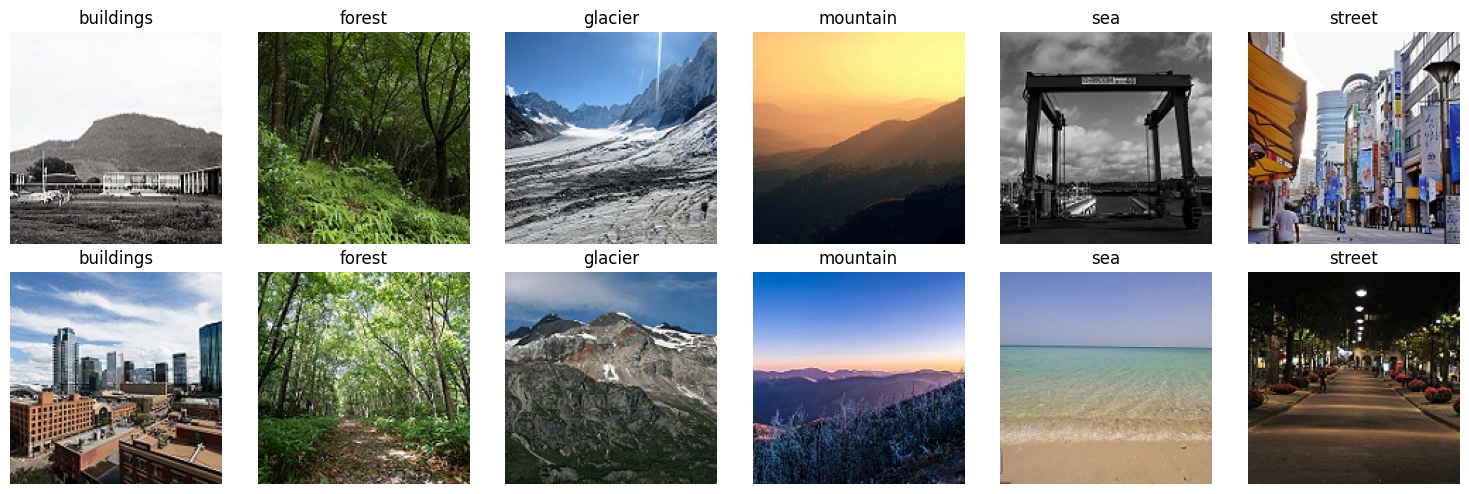

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [3]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

## Part 2: Convolution and Parameters by Hand
### Task 2.1: Reproduce the lecture's convolution

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


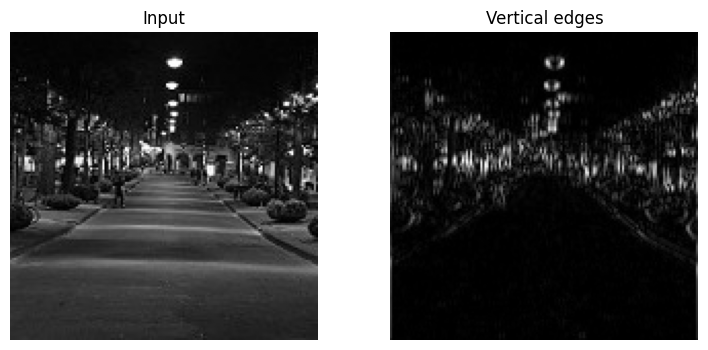

In [4]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

### Task 2.2: Why convolutions, in numbers

In [5]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')   # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')    # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


## Part 3: Transforms and Data Loaders

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


## Part 4: The Training Loop and Feature Extraction
### Task 4.1: A reusable training loop

In [7]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                         # forward pass
            loss = F.cross_entropy(logits, yb)         # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                        # backpropagation
                optimizer.step()                       # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

### Task 4.2: Freeze the body, train a new head

In [2]:
import os, glob, torch, torch.nn as nn
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

# ---------- 1. Data ----------
DATA_DIR = '/kaggle/input/datasets/puneet6060/intel-image-classification'

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([transforms.Resize((224, 224)),
                               transforms.RandomHorizontalFlip(),
                               transforms.ToTensor(), norm])
val_tf = transforms.Compose([transforms.Resize((224, 224)),
                             transforms.ToTensor(), norm])

train_ds = datasets.ImageFolder(f'{DATA_DIR}/seg_train/seg_train', train_tf)
val_ds   = datasets.ImageFolder(f'{DATA_DIR}/seg_test/seg_test', val_tf)
classes  = train_ds.classes
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds, batch_size=32, num_workers=2)
print('Classes:', classes, '| train:', len(train_ds), '| val:', len(val_ds))

# ---------- 2. Helpers ----------
def count(m):
    return sum(p.numel() for p in m.parameters())

def evaluate(model):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
            total += y.size(0)
    return correct / total

def fit(model, opt, epochs, history):
    loss_fn = nn.CrossEntropyLoss()
    best = 0.0
    for ep in range(epochs):
        model.train()
        run_loss = 0.0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            run_loss += loss.item() * x.size(0)
        acc = evaluate(model)
        history.append({'epoch': ep + 1, 'loss': run_loss / len(train_ds), 'val_acc': acc})
        best = max(best, acc)
        print(f'Epoch {ep+1}/{epochs}  loss={history[-1]["loss"]:.4f}  val_acc={acc:.3f}')
    return best

# ---------- 3. Model: weights kisi bhi tareeqe se ----------
def load_resnet18():
    """Returns (model, pretrained_flag)"""
    # (a) local .pth file (Kaggle input ya current folder)
    files = glob.glob('/kaggle/input/**/resnet18*.pth', recursive=True) + glob.glob('resnet18*.pth')
    for f in files:
        try:
            m = models.resnet18(weights=None)
            m.load_state_dict(torch.load(f, map_location='cpu'))
            print('Pretrained weights local file se load hue:', f)
            return m, True
        except Exception as e:
            print('File', f, 'load nahi hui:', e)
    # (b) internet se download
    try:
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        print('Pretrained weights download ho gaye.')
        return m, True
    except Exception as e:
        print('\n!! Pretrained weights nahi mile (internet off hai).')
        print('!! Random weights se full training chalegi, accuracy kam hogi.')
        print('!! Behtar result ke liye Settings -> Internet -> On karke dobara chalayein.\n')
        return models.resnet18(weights=None), False

model, pretrained = load_resnet18()

if pretrained:
    for p in model.parameters():
        p.requires_grad = False                            # body freeze
model.fc = nn.Linear(model.fc.in_features, len(classes))   # naya 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

# ---------- 4. Train ----------
history = []
if pretrained:
    opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)    # feature extraction
    epochs = 3
else:
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)       # random weights: sab train karo
    epochs = 5
best = fit(model, opt, epochs=epochs, history=history)
print(f'Best validation accuracy: {best:.3f}')

Device: cpu
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street'] | train: 14034 | val: 3000
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth

!! Pretrained weights nahi mile (internet off hai).
!! Random weights se full training chalegi, accuracy kam hogi.
!! Behtar result ke liye Settings -> Internet -> On karke dobara chalayein.

Trainable 11,179,590 of 11,179,590 parameters
Epoch 1/5  loss=0.9115  val_acc=0.747
Epoch 2/5  loss=0.6448  val_acc=0.778
Epoch 3/5  loss=0.5512  val_acc=0.810
Epoch 4/5  loss=0.4914  val_acc=0.809
Epoch 5/5  loss=0.4453  val_acc=0.845
Best validation accuracy: 0.845


## Part 5: Fine-Tuning and Learning Curves
### Task 5.1: Unfreeze layer4 with a smaller learning rate

In [3]:
for p in model.layer4.parameters():
    p.requires_grad = True                      # unfreeze the last block

opt = torch.optim.Adam([{'params': model.layer4.parameters(), 'lr': 1e-4}, {'params': model.fc.parameters(), 'lr': 1e-3}])     # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 11,179,590
Epoch 1/3  loss=0.3885  val_acc=0.869
Epoch 2/3  loss=0.3544  val_acc=0.878
Epoch 3/3  loss=0.3486  val_acc=0.881
Best validation accuracy, fine-tuned: 0.881


### Task 5.2: Plot the learning curves

In [ ]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')   # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

**Part 06 Test Once, Then Study the Errors******

Test accuracy: 0.897
Test accuracy percentage: 89.70%

Classification Report:
              precision    recall  f1-score   support

   buildings      0.894     0.888     0.891       312
      forest      0.979     0.979     0.979       337
     glacier      0.848     0.815     0.831       341
    mountain      0.837     0.868     0.852       349
         sea      0.902     0.892     0.897       361
      street      0.920     0.933     0.927       406

    accuracy                          0.897      2106
   macro avg      0.897     0.896     0.896      2106
weighted avg      0.897     0.897     0.897      2106



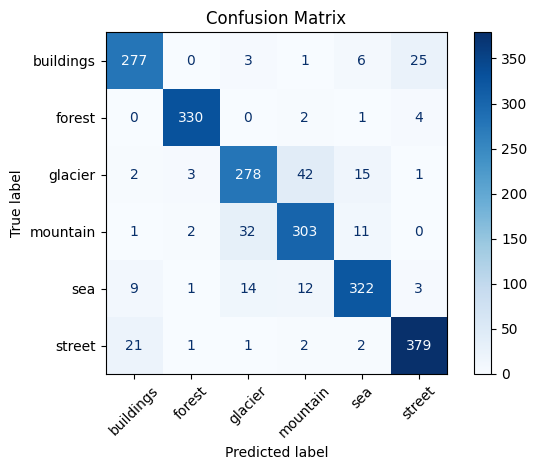

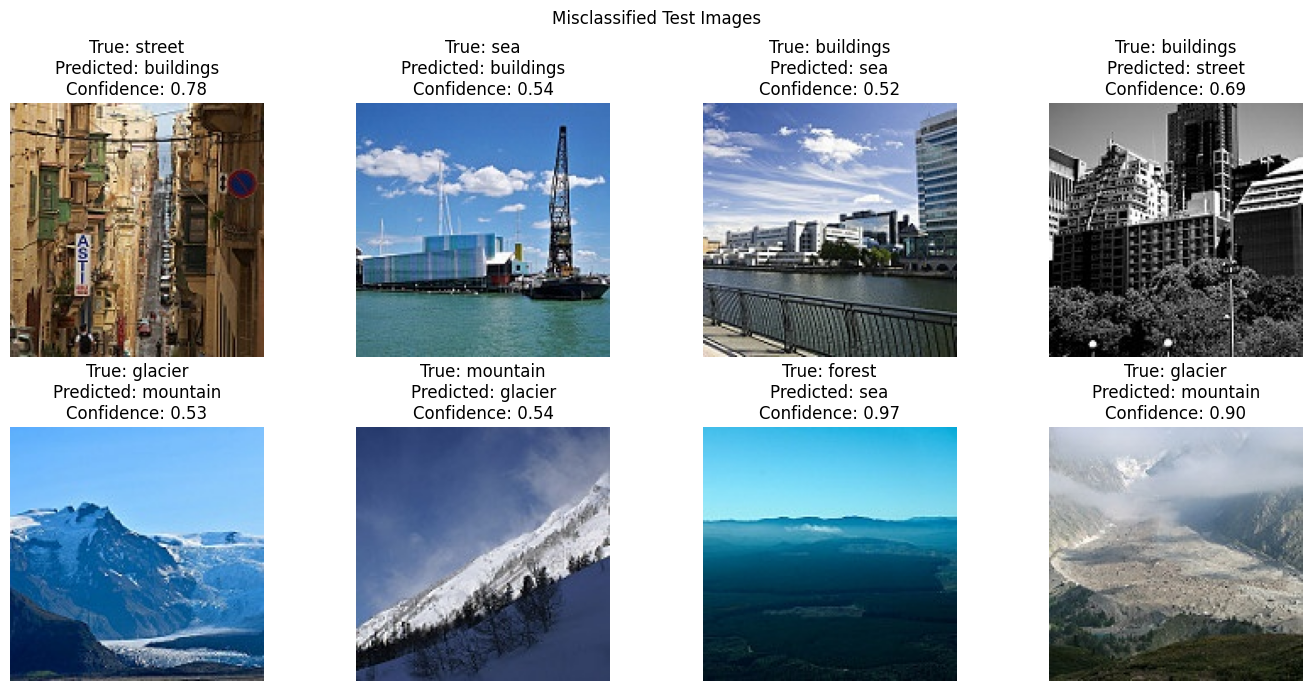


Single Image Prediction
True class: mountain
buildings       logit:   -2.40 probability: 0.001
forest          logit:   -4.80 probability: 0.000
glacier         logit:    2.42 probability: 0.167
mountain        logit:    4.03 probability: 0.831
sea             logit:   -3.71 probability: 0.000
street          logit:   -5.40 probability: 0.000


In [28]:

# ==========================================
# TASK 6.2: MODEL EVALUATION
# ==========================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Set device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

# 2. Create test DataLoader
test_dl = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False
)

# 3. Predict test images
probs = []
preds = []
labels = []

with torch.no_grad():
    for xb, yb in test_dl:
        xb = xb.to(device)

        outputs = model(xb)
        p = F.softmax(outputs, dim=1).cpu()

        probs.append(p)
        preds.append(p.argmax(dim=1))
        labels.append(yb.cpu())

# 4. Combine all batches
probs = torch.cat(probs)
preds = torch.cat(preds)
labels = torch.cat(labels)

# 5. Calculate test accuracy
accuracy = (preds == labels).float().mean().item()

print(f"Test accuracy: {accuracy:.3f}")
print(f"Test accuracy percentage: {accuracy * 100:.2f}%")

# 6. Print classification report
print("\nClassification Report:")

print(classification_report(
    labels.numpy(),
    preds.numpy(),
    target_names=classes,
    digits=3,
    zero_division=0
))

# 7. Display confusion matrix
cm = confusion_matrix(
    labels.numpy(),
    preds.numpy()
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

display.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# 8. Display incorrectly classified images
wrong = torch.where(preds != labels)[0][:8]

if len(wrong) > 0:

    fig, axes = plt.subplots(
        2, 4,
        figsize=(14, 7)
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, i in zip(axes.flat, wrong.tolist()):

        # test_ds ek Subset hai (random_split se bana), is liye asal
        # ImageFolder (.dataset) aur asal index (.indices) se path nikalein
        real_idx = test_ds.indices[i]
        path, _ = test_ds.dataset.samples[real_idx]

        img = Image.open(path).convert("RGB")

        ax.imshow(img)

        true_class = classes[labels[i].item()]
        predicted_class = classes[preds[i].item()]
        confidence = probs[i].max().item()

        ax.set_title(
            f"True: {true_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence:.2f}"
        )

        ax.axis("off")

    plt.suptitle("Misclassified Test Images")
    plt.tight_layout()
    plt.show()

else:
    print("All test images were classified correctly!")

# 9. Inspect the first test image
x0, y0 = test_ds[0]

with torch.no_grad():

    logits = model(
        x0.unsqueeze(0).to(device)
    ).cpu().squeeze(0)

    p = F.softmax(logits, dim=0)

print("\nSingle Image Prediction")
print("True class:", classes[y0])

for c, z, q in zip(
    classes,
    logits.tolist(),
    p.tolist()
):
    print(
        f"{c:15s} "
        f"logit: {z:7.2f} "
        f"probability: {q:.3f}"
    )

## Part 7: Save and Share

In [29]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)
